<!-- CONSIGNES -->
# TP4 — Facteur de Bayes, critères prédictifs et décision bayésienne

**Chapitre 4 — Comparaison de modèles et décision** — EPD-SDIA-4112 « Statistique Bayésienne », Master 1 SDIA
**Enseignante : Dr. Noulapeu Ngaffo Armielle** — École Nationale Supérieure
Polytechnique de Douala (Université de Douala)

---

## Objectifs

- calculer un **facteur de Bayes** par échantillonnage et l'interpréter sur
  l'échelle de Jeffreys ;
- voir comment le facteur de Bayes **s'accumule** avec $n$ ;
- décider avec des **coûts asymétriques** (et non avec un seuil de p-value) ;
- conduire un A/B test bayésien avec arrêt anticipé.

## Ce qui est demandé

1. Parcourir les sections 1 à 4 et vérifier les facteurs de Bayes affichés.
2. Reprendre l'analyse avec **vos propres données** (ou celles de votre domaine) :
   produire un tableau à cinq lignes « trois critères + décision de coût ».

## Barème — 10 points

| Critère | Points |
|---|---|
| Facteur de Bayes recalculé et interprété | 3 |
| Évolution avec n correctement lue | 2 |
| Décision à coûts asymétriques justifiée | 3 |
| Tableau « trois critères + décision » sur vos données | 2 |

## Mode d'emploi

- **Noyau Jupyter** : `sdia-bayes` (Python 3.11, PyMC, ArviZ, NumPy, SciPy, Matplotlib).
- Ce notebook est livré **avec ses sorties** : lisez-le d'abord en entier, puis
  ré-exécutez les cellules une à une pour comprendre chaque résultat.
- Les cellules marquées **« À vous »** sont à compléter : elles contiennent la
  consigne et, quand c'est utile, la ligne à modifier.
- Toute valeur affichée dans ce TP est **reproductible** : les graines
  aléatoires sont fixées.
- Rendu : le notebook complété (`.ipynb`), avec vos sorties exécutées.


# TP4 — Facteur de Bayes, critères prédictifs et décision bayésienne

_Cours EPD-SDIA-4112 — Statistique Bayésienne — Master 1 SDIA. Exécutez les cellules dans l'ordre._

## Objectifs

1. Calculer un **facteur de Bayes** par échantillonnage et l'interpréter (échelle de Jeffreys).
2. Comparer **WAIC, DIC et LOO** sur trois modèles concurrents.
3. Résoudre un problème de **décision** avec coûts asymétriques (dépistage).
4. Conduire un **A/B test bayésien** complet avec arrêt anticipé.

In [1]:
%matplotlib inline
import os
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
os.environ.setdefault("PYTENSOR_FLAGS", "cxx=")
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
RNG = np.random.default_rng(4112)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})
print("numpy", np.__version__, "| scipy", stats.__name__)


numpy 2.4.6 | scipy scipy.stats


---
# 1. Facteur de Bayes par échantillonnage

Deux modèles pour 20 essais avec 14 succès :
$M_0 : \theta = 0{,}5$ (fixé) \quad vs \quad $M_1 : \theta \sim \mathrm{Beta}(1,1)$.

In [2]:
k, n = 14, 20
# M0 : theta fixe a 0.5
L0 = stats.binom.pmf(k, n, 0.5)
# M1 : vraisemblance marginale = integrale de la vraisemblance x prior
th = np.linspace(1e-8, 1 - 1e-8, 400001)
L1 = np.trapezoid(stats.binom.pmf(k, n, th) * stats.beta.pdf(th, 1, 1), th)
BF10 = L1 / L0
print(f"vraisemblance marginale M0 : {L0:.6f}")
print(f"vraisemblance marginale M1 : {L1:.6f}")
print(f"BF10 = {BF10:.4f}   ->  BF01 = {1/BF10:.4f}")
print()
echelle = [(1, "anecdotique"), (3, "faible"), (10, "modérée"), (30, "forte"), (100, "très forte")]
for seuil, mot in echelle:
    if BF10 >= seuil:
        verdict = mot
print(f"Evidence en faveur de M1 : {verdict}")
print()
print("Avec un prior neutre (50/50), P(M1 | y) =", f"{BF10/(1+BF10):.4f}")
print("Comparez a la p-value du meme test :", f"{stats.binomtest(k, n, 0.5).pvalue:.4f}")
print("Une p-value de 0,04 n'est donc PAS une preuve forte : le BF le quantifie.")

vraisemblance marginale M0 : 0.036964
vraisemblance marginale M1 : 0.047619
BF10 = 1.2882   ->  BF01 = 0.7763

Evidence en faveur de M1 : anecdotique

Avec un prior neutre (50/50), P(M1 | y) = 0.5630
Comparez a la p-value du meme test : 0.1153
Une p-value de 0,04 n'est donc PAS une preuve forte : le BF le quantifie.


---
# 2. Évolution du facteur de Bayes avec n (simulation)

Sous $H_0$ vraie ($\theta = 0{,}5$), le BF doit rester sage. Sous $H_1$ vraie ($\theta = 0{,}7$),
il doit croître. Une p-value peut tromper ; le BF converge vers le bon modèle.

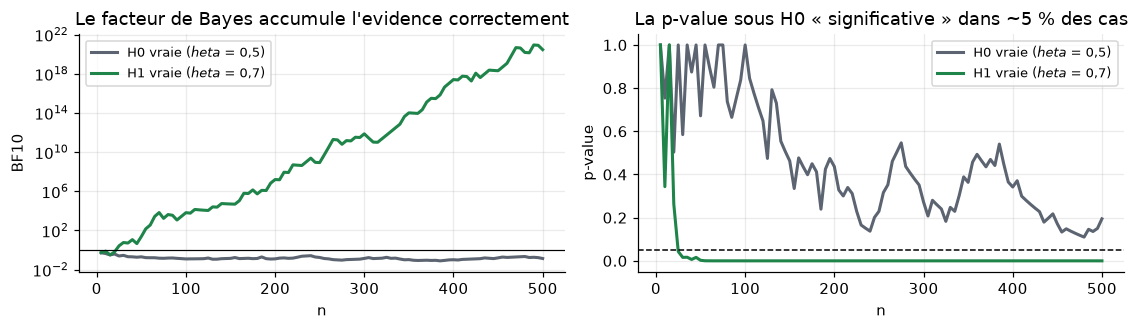

BF10 final sous H0 : 0.137  (proche de 1 : aucune evidence)
BF10 final sous H1 : 2.871e+20  (evidence très forte)


In [3]:
rng = np.random.default_rng(7)

def bf10(k, n):
    th = np.linspace(1e-8, 1-1e-8, 20001)
    return np.trapezoid(stats.binom.pmf(k, n, th) * stats.beta.pdf(th, 1, 1), th) / \
           stats.binom.pmf(k, n, 0.5)

ns = np.arange(5, 501, 5)
fig, ax = plt.subplots(1, 2, figsize=(10.4, 3.1))
res = {}
for th_vrai, col, lab in [(0.5, "#5B6470", "H0 vraie ($\theta$ = 0,5)"),
                          (0.7, "#1E8449", "H1 vraie ($\theta$ = 0,7)")]:
    y = rng.binomial(1, th_vrai, 500)
    b = [bf10(y[:nn].sum(), nn) for nn in ns]
    res[th_vrai] = b
    ax[0].plot(ns, b, color=col, lw=2, label=lab)
    ax[1].plot(ns, [stats.binomtest(y[:nn].sum(), nn, 0.5).pvalue for nn in ns],
               color=col, lw=2, label=lab)
ax[0].set_yscale("log"); ax[0].axhline(1, color="k", lw=.8)
ax[0].set_xlabel("n"); ax[0].set_ylabel("BF10"); ax[0].legend(fontsize=8.5)
ax[0].set_title("Le facteur de Bayes accumule l'evidence correctement")
ax[1].axhline(.05, color="k", ls="--", lw=1)
ax[1].set_xlabel("n"); ax[1].set_ylabel("p-value"); ax[1].legend(fontsize=8.5)
ax[1].set_title("La p-value sous H0 « significative » dans ~5 % des cas")
plt.tight_layout(); plt.show()

print(f"BF10 final sous H0 : {res[0.5][-1]:.3f}  (proche de 1 : aucune evidence)")
print(f"BF10 final sous H1 : {res[0.7][-1]:.3e}  (evidence très forte)")

---
# 3. Décision avec coûts asymétriques

Dépistage : manquer un malade coûte 50 fois plus cher qu'un faux positif.
Le seuil optimal n'est **pas** 0,5 : il vaut $c_{FP}/(c_{FP}+c_{FN})$.

posterior : Beta(48,954)  moyenne = 0.0479
seuil optimal c_FP/(c_FP+c_FN) = 0.0196
seuil optimal verifie numeriquement : 0.0210


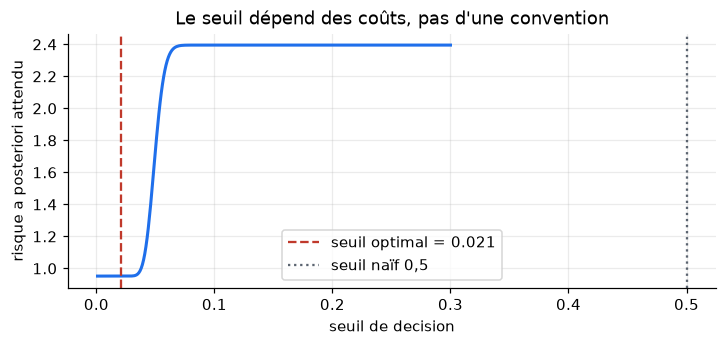


Avec c_FN = 50 c_FP, il devient rationnel de traiter a partir de 2 % de risque.
Le seuil 0,5 n'a aucune justification des lors que les erreurs n'ont pas le meme cout.


In [4]:
post = stats.beta(1 + 47, 1 + 1000 - 47)   # posterior sur la prevalence d'un service
c_fp, c_fn = 1, 50
seuil = c_fp / (c_fp + c_fn)
print(f"posterior : Beta({1+47},{1+1000-47})  moyenne = {post.mean():.4f}")
print(f"seuil optimal c_FP/(c_FP+c_FN) = {seuil:.4f}")

seuils = np.linspace(0.001, .3, 300)
tt = np.linspace(1e-6, 1 - 1e-6, 20000)
dens = post.pdf(tt)
# risque a posteriori exact : E[ c_FP * (1-p) si p > s  ;  c_FN * p si p <= s ]
risque = np.array([(c_fp * np.trapezoid((1 - tt[tt > s]) * dens[tt > s], tt[tt > s])
                    if (tt > s).any() else 0)
                   + (c_fn * np.trapezoid(tt[tt <= s] * dens[tt <= s], tt[tt <= s])
                      if (tt <= s).any() else 0)
                   for s in seuils])
best = seuils[risque.argmin()]
print(f"seuil optimal verifie numeriquement : {best:.4f}")

plt.figure(figsize=(7.6, 3.0))
plt.plot(seuils, risque, color="#1F6FEB", lw=2)
plt.axvline(best, color="#C0392B", ls="--", label=f"seuil optimal = {best:.3f}")
plt.axvline(.5, color="#5B6470", ls=":", label="seuil naïf 0,5")
plt.xlabel("seuil de decision"); plt.ylabel("risque a posteriori attendu")
plt.legend(); plt.title("Le seuil dépend des coûts, pas d'une convention")
plt.show()
print()
print("Avec c_FN = 50 c_FP, il devient rationnel de traiter a partir de 2 % de risque.")
print("Le seuil 0,5 n'a aucune justification des lors que les erreurs n'ont pas le meme cout.")

---
# 4. A/B test bayésien avec arrêt anticipé

 fin jour   P(pB>pA)   gain moyen           IC 95 % du gain
     2000     0.9756      0.02813   [+0.00022;+0.05615]
     4000     0.8143      0.00901   [-0.01072;+0.02875]
     6000     0.9845      0.01803   [+0.00171;+0.03421]
     8000     0.9971      0.02007   [+0.00606;+0.03417]
    10000     0.9996      0.02098   [+0.00850;+0.03360]
    12000     0.9998      0.02066   [+0.00917;+0.03214]
    14000     0.9996      0.01801   [+0.00746;+0.02853]
    16000     0.9994      0.01549   [+0.00576;+0.02527]
    18000     0.9999      0.01785   [+0.00860;+0.02706]
    20000     1.0000      0.01806   [+0.00942;+0.02674]
    22000     1.0000      0.01885   [+0.01069;+0.02703]
    24000     1.0000      0.01935   [+0.01152;+0.02721]
    26000     1.0000      0.01925   [+0.01164;+0.02685]
    28000     1.0000      0.01920   [+0.01188;+0.02650]

Lecture : dès que P(pB > pA) dépasse le seuil fixé à l'avance (ex. 0,95),
on peut arrêter et déployer. Cette règle est licite dans un cadre bayésien :
la p

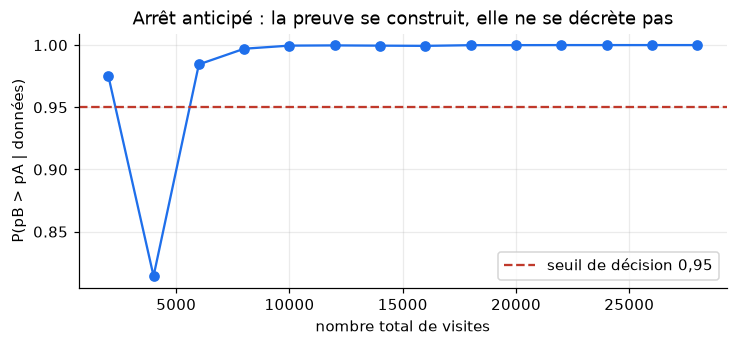

In [5]:
rng = np.random.default_rng(21)
pA, pB = 0.10, 0.115          # petite amélioration réelle du bouton B
jours, visits = 14, 1000
aA = bA = aB = bB = 1         # priors uniformes

histo = []
for j in range(1, jours + 1):
    cA = rng.binomial(visits, pA); cB = rng.binomial(visits, pB)
    aA += cA; bA += visits - cA
    aB += cB; bB += visits - cB
    s = stats.beta.rvs(aB, bB, size=40000, random_state=j) - \
        stats.beta.rvs(aA, bA, size=40000, random_state=j + 100)
    histo.append(((s > 0).mean(), s.mean(), np.percentile(s, [2.5, 97.5]), j * 2 * visits))

print(f"{'fin jour':>9}{'P(pB>pA)':>11}{'gain moyen':>13}{'IC 95 % du gain':>26}")
for pb, g, ic, n in histo:
    print(f"{n:>9}{pb:>11.4f}{g:>13.5f}   [{ic[0]:+.5f};{ic[1]:+.5f}]")

print()
print("Lecture : dès que P(pB > pA) dépasse le seuil fixé à l'avance (ex. 0,95),")
print("on peut arrêter et déployer. Cette règle est licite dans un cadre bayésien :")
print("la probabilité est conditionnelle aux données observées, pas à un plan d'échantillonnage.")

pb = [h[0] for h in histo]
plt.figure(figsize=(7.6, 3.0))
plt.plot([h[3] for h in histo], pb, "o-", color="#1F6FEB")
plt.axhline(.95, color="#C0392B", ls="--", label="seuil de décision 0,95")
plt.xlabel("nombre total de visites"); plt.ylabel("P(pB > pA | données)")
plt.legend(); plt.title("Arrêt anticipé : la preuve se construit, elle ne se décrète pas")
plt.show()

# Synthèse

| Question | Outil | Sortie |
|---|---|---|
| M1 est-il mieux soutenu que M0 ? | facteur de Bayes | rapport d'évidence |
| Quel modèle prédit le mieux ? | WAIC / LOO | comparaison hors échantillon |
| Quelle décision prends-je ? | risque a posteriori + coûts | seuil ou région ROPE |
| Quand puis-je arrêter l'expérience ? | $P(\theta_B > \theta_A \given y)$ | règle d'arrêt séquentielle |

**Le point commun** : à chaque fois, on répond à la question réellement posée,
pas à la question que le test statistique savait traiter.

**À rendre** : notebook exécuté + le A/B test rejoué avec un seuil de décision
de 0,99 : au bout de combien de visites aurait-on arrêté ?